# Baseline: YOLOv8n-seg preentrenado en COCO, **sin finetuning**

Objetivo: ver cómo rinde de base el modelo `yolov8n-seg.pt` (COCO) segmentando peces en nuestro dataset, antes de entrenar nada.

Qué hace este notebook:
1. Carga el modelo y las máscaras reales (ground truth) de **train + val + test**. Como no hay entrenamiento, los tres splits son solo "datos de test".
2. Corre inferencia con un umbral de confianza muy bajo y guarda, para cada imagen, las detecciones y el **IoU** contra la máscara real.
3. Elige el umbral de confianza **dinámicamente** (ya que el modelo no está ajustado a peces, un umbral fijo como 0.25 no tiene por qué servir).
4. Mide el IoU en todas las imágenes y grafica las **20 de mayor confianza**, las **20 de menor confianza** y las **20 de peor IoU**.

> ⚠️ **Sobre la clase `fish`:** COCO tiene 80 clases y **ninguna es pez** (se verifica en la sección 1). Por eso no se puede "filtrar la clase fish" del modelo preentrenado. Lo que hago es **ignorar la etiqueta de clase que predice el modelo** (clase-agnóstico): cualquier objeto detectado/segmentado se toma como candidato a pez. Es lo más cercano a lo pedido y, de paso, muestra con qué clases COCO "confunde" el modelo a los peces (sección 5). La clase real del dataset es una sola (`pescado`, id 0).

In [1]:
import json
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

ROOT = Path.cwd()
DATA = ROOT / "dataset"
SPLITS = ["train", "val", "test"]
IMGSZ = 640
CONF_FLOOR = 0.01     # piso de confianza de la inferencia: detecciones por debajo no se consideran nunca
MAX_DET = 10          # máximo de detecciones por imagen
N_PLOT = 20           # imágenes por gráfico

## 1. Modelo preentrenado

Se carga `yolov8n-seg.pt` y se **verifica** que sea el modelo COCO original (80 clases) y no uno finetuneado, y que `fish` no esté entre las clases.

In [2]:
model = YOLO(ROOT / "yolov8n-seg.pt")
names = model.names
print("n clases:", len(names), "| ¿hay 'fish'?:", any("fish" in n.lower() for n in names.values()))
assert len(names) == 80, "no es el modelo COCO original"
print(list(names.values()))

n clases: 80 | ¿hay 'fish'?: False
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


## 2. Datos y máscara real

Las etiquetas están en formato YOLO-seg (`clase x1 y1 x2 y2 ...` normalizado, un polígono por línea). La máscara real de cada imagen es la **unión de todos sus polígonos** rasterizados al tamaño original de la imagen. Se usan los tres splits.

In [3]:
def read_img(path):
    # np.fromfile + imdecode: soporta rutas no ASCII en Windows
    return cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_COLOR)

def read_polys(label_path, h, w):
    polys = []
    for line in label_path.read_text().splitlines():
        v = line.split()
        if len(v) >= 7:
            polys.append((np.array(v[1:], float).reshape(-1, 2) * [w, h]).round().astype(np.int32))
    return polys

def gt_mask(polys, h, w):
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, polys, 1)
    return m.astype(bool)

items = []
for s in SPLITS:
    for p in sorted((DATA / "images" / s).iterdir()):
        items.append(dict(split=s, path=p, label=DATA / "labels" / s / (p.stem + ".txt"),
                          species=p.name.split("__")[0]))
print(Counter(i["split"] for i in items), "| total:", len(items))

Counter({'train': 913, 'test': 209, 'val': 194}) | total: 1316


## 3. Inferencia (una sola vez) y IoU por cantidad de detecciones

Para poder elegir el umbral de confianza después sin repetir la inferencia, cada imagen se predice **una vez** con `conf=0.01` (muy bajo), `max_det=10`, `agnostic_nms=True` (NMS sin mirar la clase, coherente con ignorar clases) y `retina_masks=True` (máscaras a resolución original).

Detalle clave: cualquier umbral de confianza (fijo o relativo) siempre se queda con las **k detecciones más confiables**. Entonces, por imagen, guardo el IoU de la unión de las primeras `k` máscaras para `k = 0..n` (con `k=0` → predicción vacía → IoU 0). Así cualquier estrategia de umbral se evalúa después **exactamente** con solo elegir `k`, sin volver a correr el modelo ni guardar las máscaras en memoria.

El IoU es **por imagen**: `|pred ∩ GT| / |pred ∪ GT|`, con `pred` = unión de las máscaras elegidas y `GT` = unión de los polígonos reales.

In [4]:
def predict(img):
    return model.predict(img, imgsz=IMGSZ, conf=CONF_FLOOR, max_det=MAX_DET, agnostic_nms=True,
                         retina_masks=True, verbose=False)[0]

recs = []
for i, it in enumerate(items):
    img = read_img(it["path"]); h, w = img.shape[:2]
    gm = gt_mask(read_polys(it["label"], h, w), h, w)
    r = predict(img)
    confs = r.boxes.conf.cpu().numpy() if len(r.boxes) else np.zeros(0)
    clss = r.boxes.cls.cpu().numpy().astype(int) if len(r.boxes) else np.zeros(0, int)
    ious, cum = [0.0], np.zeros((h, w), bool)
    if r.masks is not None:
        ms = r.masks.data.cpu().numpy().astype(bool)           # ya viene ordenado por confianza desc.
        for m in ms:
            cum |= m
            ious.append((cum & gm).sum() / max((cum | gm).sum(), 1))
    recs.append(dict(split=it["split"], name=it["path"].name, species=it["species"],
                     confs=confs, clss=clss, ious=np.array(ious)))
    if (i + 1) % 200 == 0: print(f"{i+1}/{len(items)}")
R = pd.DataFrame(recs)
R["n_det"] = R.confs.map(len)
R["top_conf"] = R.confs.map(lambda c: float(c[0]) if len(c) else 0.0)
print("imágenes sin ninguna detección (conf>=%.2f): %d de %d" % (CONF_FLOOR, (R.n_det == 0).sum(), len(R)))

200/1316


400/1316


600/1316


800/1316


1000/1316


1200/1316


imágenes sin ninguna detección (conf>=0.01): 4 de 1316


## 4. Umbral de confianza dinámico

Un modelo sin finetuning da confianzas bajas y muy variables en peces (los "ve" como otra cosa). Un umbral fijo corta demasiado o deja pasar basura. Pruebo una familia de reglas **por imagen**:

`umbral(imagen) = max(abs, rel × confianza_máxima_de_esa_imagen)`

- `rel = 0` → umbral **fijo** `abs` (incluye el 0.25 por defecto de YOLO).
- `rel > 0` → el umbral **se adapta a cada imagen**: se queda con las detecciones cercanas a la mejor de esa imagen, y `abs` es solo un piso de ruido.
- `rel = 1` → se queda solo con la detección más confiable.

Se hace una búsqueda en grilla de `(abs, rel)` y se elige la combinación con **mayor IoU medio en `train`**. Como el modelo no se entrena, `train` funciona como set de calibración del umbral y `val`/`test` quedan como chequeo de que lo elegido generaliza (el umbral es solo 2 números, el riesgo de sobreajuste es mínimo).

Mejor en train: abs=0.05, rel=0.0 -> IoU medio 0.505


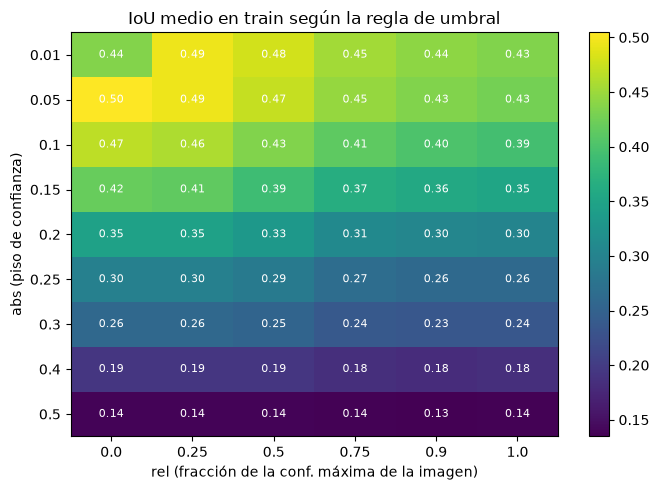

In [5]:
ABS = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
REL = [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]

def pick_k(confs, abs_t, rel_t):
    if len(confs) == 0: return 0
    return int((confs >= max(abs_t, rel_t * confs[0])).sum())

def mean_iou(df, abs_t, rel_t):
    return float(np.mean([r.ious[pick_k(r.confs, abs_t, rel_t)] for r in df.itertuples()]))

tr = R[R.split == "train"]
grid = pd.DataFrame([[mean_iou(tr, a, r) for r in REL] for a in ABS], index=ABS, columns=REL)
best_a, best_r = grid.stack().idxmax()
print(f"Mejor en train: abs={best_a}, rel={best_r} -> IoU medio {grid.loc[best_a, best_r]:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(grid.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(REL)), REL); ax.set_yticks(range(len(ABS)), ABS)
ax.set_xlabel("rel (fracción de la conf. máxima de la imagen)"); ax.set_ylabel("abs (piso de confianza)")
for (i, j), v in np.ndenumerate(grid.values): ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("IoU medio en train según la regla de umbral"); plt.colorbar(im); plt.tight_layout(); plt.show()

## 5. IoU en todas las imágenes

Se compara:
- **Umbral fijo 0.25** (default de YOLO), como referencia de "lo que pasaría sin ajustar nada".
- **Umbral dinámico** elegido arriba.
- **Oráculo** (techo): para cada imagen se elige el `k` con mejor IoU mirando el GT. **No es utilizable en la práctica**, solo indica el máximo que se podría sacar de estas detecciones con un umbral perfecto.

In [6]:
R["k_dyn"] = [pick_k(r.confs, best_a, best_r) for r in R.itertuples()]
R["iou_dyn"] = [r.ious[r.k_dyn] for r in R.itertuples()]
R["iou_025"] = [r.ious[pick_k(r.confs, 0.25, 0.0)] for r in R.itertuples()]
R["iou_oracle"] = R.ious.map(lambda a: a.max())

def summ(g):
    return pd.Series({"n": len(g), "IoU fijo 0.25": g.iou_025.mean(), "IoU dinámico": g.iou_dyn.mean(),
                      "IoU oráculo": g.iou_oracle.mean(), "mediana dinámico": g.iou_dyn.median(),
                      "% IoU>=0.5 (dinámico)": (g.iou_dyn >= 0.5).mean() * 100, "% IoU=0 (dinámico)": (g.iou_dyn == 0).mean() * 100})
tab = pd.concat([pd.DataFrame({s: summ(R[R.split == s]) for s in SPLITS}).T, summ(R).to_frame("TODAS").T])
tab.round(3)

,n,IoU fijo 0.25,IoU dinámico,IoU oráculo,mediana dinámico,% IoU>=0.5 (dinámico),% IoU=0 (dinámico)
train,913.0,0.296,0.505,0.623,0.472,47.317,2.738
val,194.0,0.307,0.482,0.588,0.427,41.753,3.093
test,209.0,0.322,0.477,0.606,0.427,41.148,2.392
TODAS,1316.0,0.302,0.497,0.615,0.454,45.517,2.736


IoU medio por especie (todas las imágenes):


,n,iou_dyn,iou_fijo_025
species,,,
boga,127,0.450,0.318
dorado,188,0.485,0.315
palometa,357,0.578,0.358
sabalo,269,0.558,0.330
surubi_pintado,104,0.415,0.208
tararira,271,0.392,0.218


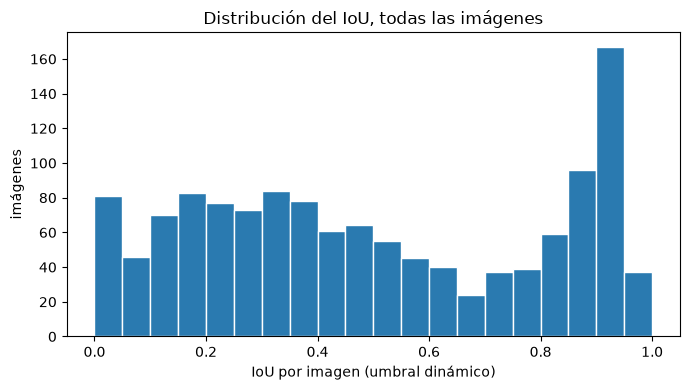

In [7]:
print("IoU medio por especie (todas las imágenes):")
display(R.groupby("species").agg(n=("iou_dyn", "size"), iou_dyn=("iou_dyn", "mean"), iou_fijo_025=("iou_025", "mean")).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(R.iou_dyn, bins=20, range=(0, 1), color="#2a7ab0", edgecolor="w")
ax.set_xlabel("IoU por imagen (umbral dinámico)"); ax.set_ylabel("imágenes"); ax.set_title("Distribución del IoU, todas las imágenes")
plt.tight_layout(); plt.show()

### ¿Con qué clases COCO detecta peces el modelo?

Como COCO no tiene `fish`, se cuenta qué clase le asigna el modelo a la detección **más confiable** de cada imagen. Sirve para entender si hay una clase "proxy" natural (p. ej. `bird`, `surfboard`, `knife`...) o si es un reparto disperso.

In [8]:
top_cls = Counter(names[r.clss[0]] for r in R.itertuples() if r.n_det)
pd.Series(top_cls).sort_values(ascending=False).head(15).rename("imágenes").to_frame()

,imágenes
person,511
bird,222
banana,65
fire hydrant,48
surfboard,47
bench,33
carrot,32
elephant,25
vase,24
cake,24


## 6. Gráficos de ejemplo (todas las imágenes: train + val + test)

En cada imagen se dibujan las detecciones **que el umbral dinámico conserva** (máscara de color, caja y `clase COCO + confianza`) y el contorno real en **verde**. El título indica split, especie, confianza máxima e IoU.

- **Mayor confianza:** las 20 imágenes con la confianza máxima más alta.
- **Menor confianza:** las 20 con la confianza máxima más baja *entre las que tienen alguna detección* (las que no tienen ninguna, y por lo tanto no tienen confianza, se cuentan aparte arriba).
- **Peor IoU:** las 20 con menor IoU. Hay muchos empates en 0, así que entre ellas se priorizan las que **sí detectaron algo** (error "confiado" sobre el fondo u otro objeto), de mayor a menor confianza, antes que las que no detectaron nada.

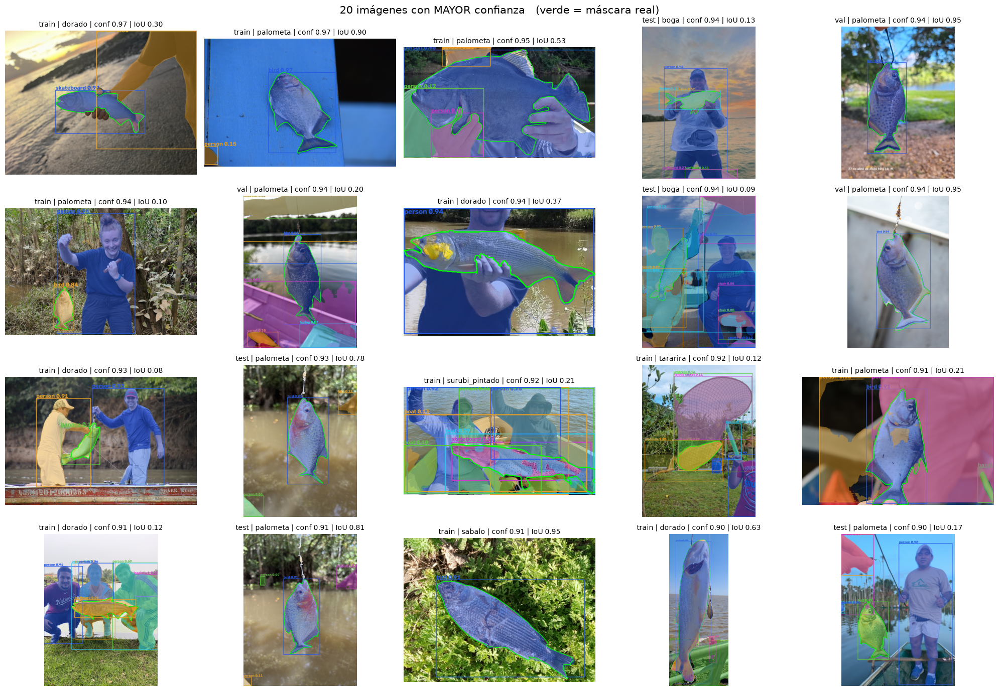

In [9]:
PALETTE = [(230, 90, 40), (40, 160, 230), (60, 200, 90), (200, 60, 200), (240, 200, 40)]
path_of = {(it["split"], it["path"].name): it for it in items}

def draw(rec):
    it = path_of[(rec.split, rec.name)]
    img = read_img(it["path"]); h, w = img.shape[:2]
    r = predict(img); out = img.copy()
    for j in range(rec.k_dyn):
        col = PALETTE[j % len(PALETTE)]
        poly = r.masks.xy[j].astype(np.int32)
        ov = out.copy(); cv2.fillPoly(ov, [poly], col); out = cv2.addWeighted(ov, 0.45, out, 0.55, 0)
        x1, y1, x2, y2 = r.boxes.xyxy[j].cpu().numpy().astype(int)
        cv2.rectangle(out, (x1, y1), (x2, y2), col, max(2, w // 300))
        cv2.putText(out, f"{names[int(r.boxes.cls[j])]} {float(r.boxes.conf[j]):.2f}", (x1, max(y1 - 6, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w / 1000), col, max(2, w // 400))
    cv2.polylines(out, read_polys(it["label"], h, w), True, (0, 255, 0), max(2, w // 300))
    return out[..., ::-1]

def show(sel, title, fname):
    fig, axes = plt.subplots(4, 5, figsize=(20, 14))
    for ax, rec in zip(axes.ravel(), sel.itertuples()):
        ax.imshow(draw(rec)); ax.axis("off")
        ax.set_title(f"{rec.split} | {rec.species} | conf {rec.top_conf:.2f} | IoU {rec.iou_dyn:.2f}", fontsize=10)
    for ax in axes.ravel()[len(sel):]: ax.axis("off")
    fig.suptitle(title + "   (verde = máscara real)", fontsize=15); plt.tight_layout()
    fig.savefig(ROOT / "runs" / fname, dpi=90); plt.show()

show(R.sort_values("top_conf", ascending=False).head(N_PLOT),
     f"{N_PLOT} imágenes con MAYOR confianza", "baseline_high_conf.png")

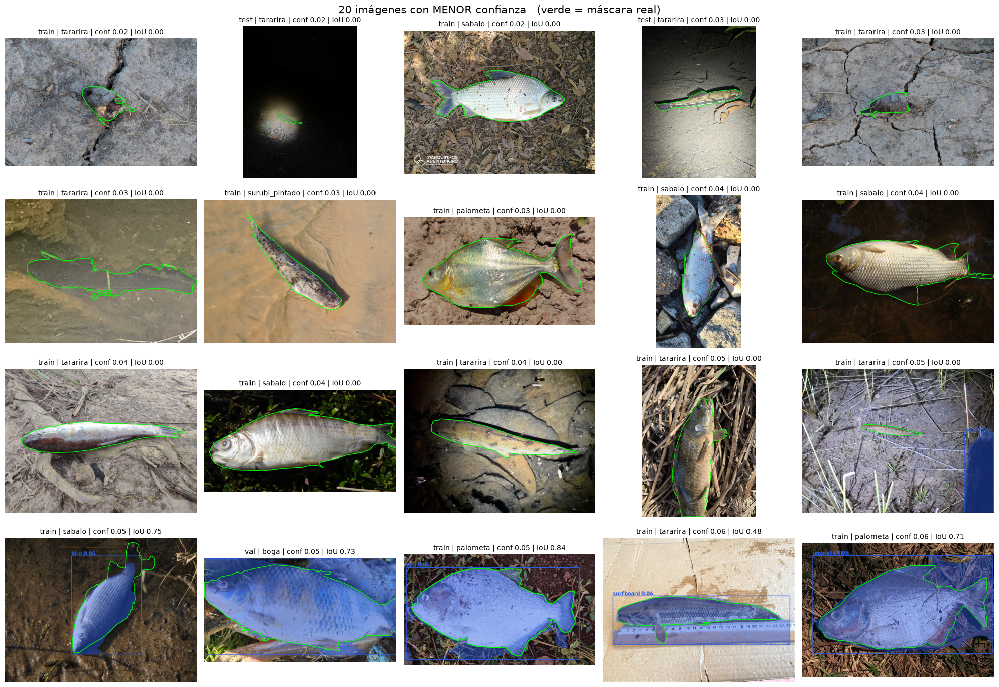

In [10]:
show(R[R.n_det > 0].sort_values("top_conf").head(N_PLOT),
     f"{N_PLOT} imágenes con MENOR confianza", "baseline_low_conf.png")

imágenes con IoU = 0: 36 de 1316


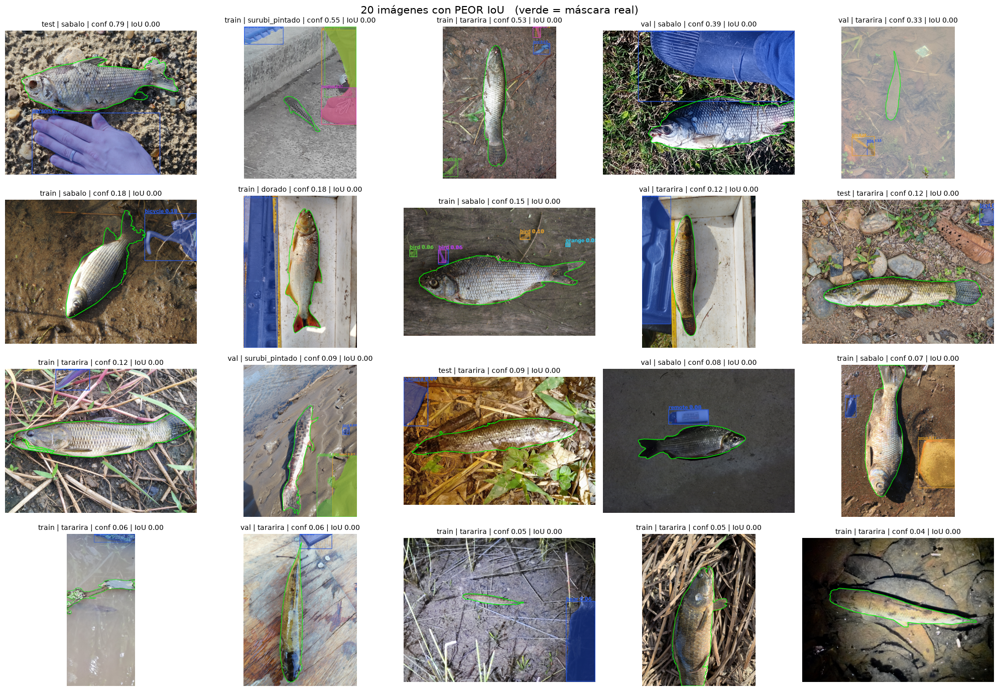

In [11]:
worst = R.assign(_det=R.k_dyn > 0).sort_values(["iou_dyn", "_det", "top_conf"], ascending=[True, False, False])
print("imágenes con IoU = 0:", int((R.iou_dyn == 0).sum()), "de", len(R))
show(worst.head(N_PLOT), f"{N_PLOT} imágenes con PEOR IoU", "baseline_worst_iou.png")

In [12]:
R.drop(columns=["confs", "clss", "ious"]).to_csv(ROOT / "runs" / "baseline_yolov8n_seg_per_image.csv", index=False)


## 7. Conclusiones del baseline

- **COCO no tiene la clase pez**, así que se evaluó de forma agnóstica a la clase (unión de todas las detecciones que pasan el umbral). La clase que el modelo le pone a los peces es dispersa: `person` (manos/pies/botas en la foto), `bird`, `banana`, `surfboard`, etc. No hay una clase "proxy" fiable, por lo que **filtrar por una clase COCO empeoraría el resultado**.
- **Umbral:** el mejor en `train` fue un **piso fijo `abs=0.05` (`rel=0`)**: la regla relativa a la confianza máxima de cada imagen *no* mejoró sobre un umbral fijo bajo (ver el heatmap). La adaptación importante fue bajar el umbral del 0.25 por defecto a 0.05, porque el modelo da confianzas bajas sobre peces.
- **IoU medio** (todas las imágenes): **0.497** con el umbral dinámico vs **0.302** con el 0.25 por defecto. Por split: train 0.505, val 0.482, test 0.477 → el umbral calibrado en train generaliza (la caída en val/test es chica). Solo ~45 % de las imágenes llegan a IoU ≥ 0.5.
- **Techo con umbral perfecto (oráculo): 0.615.** Es decir, aun eligiendo perfectamente qué detecciones conservar, el modelo sin finetuning no pasa de ~0.6: **el límite es la calidad de las máscaras/detecciones, no el umbral**. Eso es lo que debería mejorar el finetuning.
- **Mayor confianza ≠ mejor resultado:** los peores casos incluyen detecciones con confianza alta (0.79, 0.55) sobre manos, botas u otros objetos en vez del pez. La confianza del modelo COCO no es un indicador fiable de que haya un pez.
- Solo 36 de 1316 imágenes (2.7 %) tienen IoU = 0 y 4 no tienen ninguna detección; el problema dominante es la **segmentación parcial/imprecisa** más que la falta total de detección.
- Por especie, rinde mejor en `palometa` (0.58) y `sabalo` (0.56), y peor en `tararira` (0.39) y `surubi_pintado` (0.42) (cuerpos alargados y con textura que se confunde con el fondo).

Salidas: `runs/baseline_high_conf.png`, `runs/baseline_low_conf.png`, `runs/baseline_worst_iou.png` y `runs/baseline_yolov8n_seg_per_image.csv` (IoU y confianza por imagen).
